<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS08/tugas2_js08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Import library dan mengambil dataset Iris**

In [1]:
!pip install hdbscan -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# Memuat dataset Iris
iris = load_iris()
X = iris.data
y = iris.target

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Nama fitur:", iris.feature_names)
print("Label asli:", iris.target_names)

Jumlah data: 150
Jumlah fitur: 4
Nama fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Label asli: ['setosa' 'versicolor' 'virginica']


**2. Standardisasi dan clustering HDBSCAN**

In [2]:
# Standardisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Membuat model HDBSCAN
model = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

# Melakukan clustering
labels = model.fit_predict(X_scaled)

# Menghitung jumlah cluster dan noise
cluster_unik = set(labels) - {-1}
jumlah_cluster = len(cluster_unik)
jumlah_noise = np.sum(labels == -1)

print("Jumlah cluster terbentuk:", jumlah_cluster)
print("Jumlah data noise:", jumlah_noise)
print("Jumlah data bukan noise:", np.sum(labels != -1))

print("\nJumlah anggota setiap cluster:")
print(pd.Series(labels).value_counts().sort_index())

Jumlah cluster terbentuk: 2
Jumlah data noise: 2
Jumlah data bukan noise: 148

Jumlah anggota setiap cluster:
-1     2
 0    99
 1    49
Name: count, dtype: int64


**3. Visualisasi menggunakan PCA**

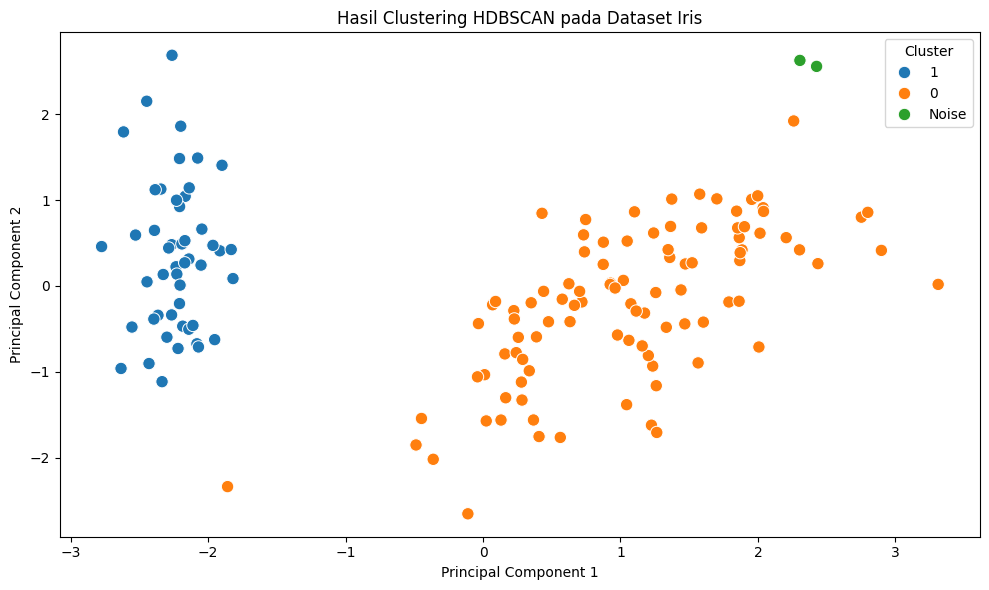

Total variasi yang dijelaskan PCA: 95.81 %


In [3]:
# Reduksi dimensi menjadi 2 komponen
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Menyiapkan data visualisasi
df_plot = pd.DataFrame({
    "PCA 1": X_pca[:, 0],
    "PCA 2": X_pca[:, 1],
    "Cluster": labels.astype(str)
})

# Mengubah label noise agar mudah dibaca
df_plot["Cluster"] = df_plot["Cluster"].replace("-1", "Noise")

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_plot,
    x="PCA 1",
    y="PCA 2",
    hue="Cluster",
    palette="tab10",
    s=80
)

plt.title("Hasil Clustering HDBSCAN pada Dataset Iris")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Total variasi yang dijelaskan PCA:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

**4. Membandingkan hasil clustering dengan label asli**

In [4]:
# Membandingkan cluster dengan label asli
ari = adjusted_rand_score(y, labels)

print("Adjusted Rand Index (ARI):", round(ari, 4))

# Tabel perbandingan cluster dan label asli
hasil = pd.crosstab(
    pd.Series(y, name="Label Asli"),
    pd.Series(labels, name="Cluster HDBSCAN")
)

hasil.index = iris.target_names

print("\nTabel perbandingan label asli dan cluster:")
print(hasil)

Adjusted Rand Index (ARI): 0.5394

Tabel perbandingan label asli dan cluster:
Cluster HDBSCAN  -1   0   1
setosa            0   1  49
versicolor        0  50   0
virginica         2  48   0


**Analisis Hasil Clustering HDBSCAN pada Dataset Iris**

Berdasarkan hasil pengujian menggunakan algoritma HDBSCAN, diperoleh nilai Adjusted Rand Index (ARI) sebesar 0,5394. Nilai tersebut menunjukkan bahwa hasil clustering memiliki kesesuaian yang cukup baik, tetapi belum sepenuhnya sesuai dengan label asli dataset Iris.

Berdasarkan tabel perbandingan, cluster 1 terdiri dari 49 data Setosa dan 1 data Versicolor. Cluster 0 terdiri dari 50 data Versicolor dan 48 data Virginica. Sementara itu, terdapat 2 data Virginica yang dikategorikan sebagai noise oleh HDBSCAN.

Hasil tersebut menunjukkan bahwa jenis bunga Setosa cenderung terpisah dengan baik dari jenis lainnya. Sebaliknya, bunga Versicolor dan Virginica masih berada dalam cluster yang sama karena karakteristik fitur keduanya relatif mirip. HDBSCAN juga mengidentifikasi 2 data Virginica sebagai noise karena data tersebut tidak memenuhi kriteria kepadatan cluster berdasarkan parameter yang digunakan.

Dengan demikian, hasil clustering HDBSCAN cukup mampu mengenali struktur kelompok pada dataset Iris, tetapi belum memisahkan ketiga jenis bunga secara sempurna. Hal ini wajar karena HDBSCAN merupakan algoritma unsupervised learning yang mengelompokkan data berdasarkan kepadatan, bukan berdasarkan label kelas yang telah tersedia.